# Chapter 67: Optimal Commodity, Income, and Capital Taxation

This notebook reruns four worked examples from the chapter: how a tax on interest compounds over the saving horizon, the Ramsey inverse-elasticity rule, the incentive limit on redistribution between two workers, and the Ramsey social discount rate. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def future_value(pv, r, T):
    """pv (1 + r)^T."""
    return pv * (1.0 + r) ** T


def present_value(fv, r, T):
    """fv / (1 + r)^T."""
    return fv / (1.0 + r) ** T


def ramsey_discount_rate(rho, eta, g):
    """Ramsey rule r = rho + eta g."""
    return rho + eta * g


def after_tax_return(r, tau):
    """Net return r (1 - tau). Principle: chamley-judd-zero-long-run-capital-tax-result.

    Book (ch067): 0.045(1 - 0.25) = 0.03375.
    """
    return r * (1 - tau)


def ramsey_rates(eps_list, contraction):
    """Proportional rates tau_i = contraction / |eps_i| that cut each compensated demand by the same share.

    Principle: ramsey-inverse-elasticity-rule. Book (ch067): eps = (-0.40, -1.20), contraction 0.012
    gives tau_b = 0.03 and tau_d = 0.01.
    """
    return [contraction / abs(e) for e in eps_list]


def specific_tax_revenue(tau, p, x, contraction=0.0):
    """Revenue sum of (tau_i p_i) x_i (1 - contraction) for proportional rates on prices p and quantities x.

    Principle: ramsey-inverse-elasticity-rule. Book (ch067): taxes 0.03(20) = 0.60 and 0.01(40) = 0.40,
    quantities 988 and 494, R = 0.60(988) + 0.40(494) = 790.4.
    Returns dict with per-unit taxes, post-tax quantities and revenue.
    """
    unit = [ti * pi for ti, pi in zip(tau, p)]
    qty = [xi * (1 - contraction) for xi in x]
    return {"unit_taxes": unit, "quantities": qty, "revenue": sum(u * q for u, q in zip(unit, qty))}


def ic_screening_cap(y_L, y_H, e, e_mimic, x):
    """Two-type redistribution x from high to low earner; high type mimics if 48,000 + x - e_mimic beats honest.

    Principle: mirrlees-optimal-income-tax-tradeoff. Book (ch067): y = 48,000 and 96,000, e = 18,000,
    e_mimic = 4,000: honest 78,000 - x, mimic 44,000 + x, cap x <= 17,000; x = 18,000 gives 60,000
    against 62,000 (violated).
    """
    honest = y_H - x - e
    mimic = y_L + x - e_mimic
    return {"honest": honest, "mimic": mimic, "cap": (y_H - y_L - e + e_mimic) / 2, "ic_holds": honest >= mimic,
            "c_low": y_L + x, "c_high": y_H - x, "u_low": y_L + x - e}


plt.rcParams.update(HOUSE_RC)


choice = SimpleNamespace(future_value=future_value, present_value=present_value, ramsey_discount_rate=ramsey_discount_rate)


public = SimpleNamespace(after_tax_return=after_tax_return, ramsey_rates=ramsey_rates, specific_tax_revenue=specific_tax_revenue)


information = SimpleNamespace(ic_screening_cap=ic_screening_cap)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'chamley-judd-zero-long-run-capital-tax-result': {'saving': 1500,
                                                   'r': 0.045,
                                                   'tau': 0.25,
                                                   'T': 35,
                                                   'fv_notax': 7001.02,
                                                   'net_r': 0.03375,
                                                   'fv_tax': 4793.3,
                                                   'ratio': 0.6847,
                                                   'shortfall_pct': 31.53,
                                                   'T10': 10,
                                                   'fv_notax_10': 2329.45,
                                                   'fv_tax_10': 2090.48,
                                                   'shortfall_pct_10': 10.26},
 'ramsey-inverse-elasticity-rule': {'eps_b': -0.4,
                                    'eps_d': -1.2,
                                    'contraction': 0.012,
                                    'tau_b': 0.03,
                                    'tau_d': 0.01,
                                    'p_b': 20,
                                    'x_b': 1000,
                                    'p_d': 40,
                                    'x_d': 500,
                                    'x_b_new': 988,
                                    'x_d_new': 494,
                                    'unit_b': 0.6,
                                    'unit_d': 0.4,
                                    'R': 790.4},
 'mirrlees-optimal-income-tax-tradeoff': {'y_L': 48000,
                                          'y_H': 96000,
                                          'e': 18000,
                                          'e_mimic': 4000,
                                          'U_L': 30000,
                                          'U_H': 78000,
                                          'x_try': 18000,
                                          'honest_try': 60000,
                                          'mimic_try': 62000,
                                          'cap': 17000,
                                          'c_low_cap': 65000,
                                          'c_high_cap': 79000,
                                          'total': 144000,
                                          'u_high_cap': 61000},
 'ramsey-social-discounting-rule': {'cost': 45,
                                    'benefit': 120,
                                    'T': 35,
                                    'rho': 0.008,
                                    'eta': 1.4,
                                    'g': 0.018,
                                    'r': 0.0332,
                                    'PV': 38.26,
                                    'g2': 0.004,
                                    'r2': 0.0136,
                                    'PV2': 74.79,
                                    'g3': -0.01,
                                    'r3': -0.006},
 'constructed': {'chamley-judd-zero-long-run-capital-tax-result': {'tau': [0.4], 'T': [20]},
                 'ramsey-inverse-elasticity-rule': {'eps_d': [-0.8, -1.6],
                                                    'contraction': [0.006, 0.024]},
                 'mirrlees-optimal-income-tax-tradeoff': {'e_mimic': [0, 8000], 'x': [15000]},
                 'ramsey-social-discounting-rule': {'eta': [1.0, 2.0],
                                                    'PV_at_g3_computed': 148.14}}}


def short(x, digits=5):
    """Up to `digits` decimals, trailing zeros removed: 0.03375, 0.01, 1."""
    return f"{x:.{digits}f}".rstrip("0").rstrip(".")


def capital_tax_picture(tau=0.25, years=35):
    bv = BV["chamley-judd-zero-long-run-capital-tax-result"]
    pv, r = bv["saving"], bv["r"]
    net = public.after_tax_return(r, tau)
    fv0 = choice.future_value(pv, r, years)
    fv1 = choice.future_value(pv, net, years)
    ratio = fv1 / fv0
    gap = 100 * (1 - ratio)
    ts = np.linspace(0, 35, 200)
    fig, ax = new_figure()
    g0 = [choice.future_value(pv, r, x) for x in ts]
    g1 = [choice.future_value(pv, net, x) for x in ts]
    ax.plot(ts, g0, color=PALETTE["navy"], linewidth=2.2)
    if tau > 0:
        ax.plot(ts, g1, color=PALETTE["teal"], linewidth=2.2)
        inside = ts <= years
        ax.fill_between(ts[inside], np.array(g1)[inside], np.array(g0)[inside], color=PALETTE["gold"], alpha=0.2)
    label(ax, 30, choice.future_value(pv, r, 30), "no tax, 4.5%", col="navy", dx=-8, dy=8, ha="right")
    vline(ax, years, None, col="grey")
    if tau > 0:
        label(ax, 26, choice.future_value(pv, net, 26), f"taxed, {num(100 * net, 3)}%", col="teal", dx=8, dy=-8,
              ha="left", va="top")
        mark(ax, years, fv0, f"{num(fv0)}", col="navy", dx=-8, dy=6, ha="right")
        mark(ax, years, fv1, f"{num(fv1)}", col="teal", dx=8, dy=-8, va="top")
    else:
        if years < 35:
            mark(ax, years, fv0, f"{num(fv0)} with or without the tax", col="navy", dx=8, dy=-8, va="top")
        else:
            mark(ax, years, fv0, f"{num(fv0)} with or without the tax", col="navy", dx=-8, dy=6, ha="right")
    ax.text(0.02, 0.80, f"shortfall at year {years}: {num(gap)}%",
            transform=ax.transAxes, ha="left", va="top", fontsize=10.5, color=PALETTE["gold"],
            bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})
    ax.set_xlim(0, 42)
    ax.set_ylim(0, 8000)
    ax.set_xlabel("Years saved")
    ax.set_ylabel("Value of 1,500 saved")
    metrics = {"Net return": f"{short(100 * net, 3)}%", "No-tax value": num(fv0), "Taxed value": num(fv1),
               "Ratio taxed / no tax": num(ratio, 4), "Shortfall": f"{num(gap)}%"}
    steps = [f"Net return = 0.045(1 - {short(tau, 2)}) = {short(net)}",
             f"No tax: 1,500(1.045)^{years} = {num(fv0)}",
             f"Taxed: 1,500({short(1 + net)})^{years} = {num(fv1)}",
             f"Ratio = {num(fv1)} / {num(fv0)} = {num(ratio, 4)}",
             f"Shortfall = 1 - {num(ratio, 4)} = {num(gap)}%"]
    if tau == 0:
        tail = "With no tax on interest the two paths coincide and nothing is lost."
    else:
        per_year = 100 * (1 - (1 + net) / (1 + r))
        tail = (f"Each year the taxed path falls only {num(per_year)}% further behind, but the loss compounds: "
                f"after {years} years the taxed saving is worth {num(gap)}% less.")
    interp = (f"The net return is 0.045 x (1 - {short(tau, 2)}) = {short(net)}. After {years} years 1,500 grows to "
              f"{num(fv0)} without the tax and {num(fv1)} with it, a ratio of {num(ratio, 4)}. {tail}")
    alt = (f"Growth of 1,500 saved over 35 years at 4.5 percent and at the net return {short(100 * net, 3)} percent. "
           f"At year {years} the values are {num(fv0)} and {num(fv1)}, a shortfall of {num(gap)} percent.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def ramsey_picture(eps_d=-1.2, c=0.012):
    bv = BV["ramsey-inverse-elasticity-rule"]
    eps_b = bv["eps_b"]
    tau_b, tau_d = public.ramsey_rates([eps_b, eps_d], c)
    rev = public.specific_tax_revenue([tau_b, tau_d], [bv["p_b"], bv["p_d"]], [bv["x_b"], bv["x_d"]], c)
    (u_b, u_d), (q_b, q_d) = rev["unit_taxes"], rev["quantities"]
    part_b, part_d = u_b * q_b, u_d * q_d
    ratio = tau_b / tau_d
    fig, (ax, bx) = new_figure(ncols=2)
    bar_compare(ax, ["basic\n(elasticity 0.40)", f"discretionary\n(elasticity {num(abs(eps_d), 2)})"],
                [100 * tau_b, 100 * tau_d], colors=["teal", "gold"],
                value_labels=[f"{short(100 * tau_b, 3)}%", f"{short(100 * tau_d, 3)}%"],
                ylabel="Tax rate (% of price)", xlabel="Service")
    ax.set_ylim(0, 6.9)
    ax.text(0.97, 0.97, f"basic rate = {num(ratio, 0)} x discretionary", transform=ax.transAxes, ha="right",
            va="top", fontsize=10.5, color=PALETTE["ink"])
    bar_compare(bx, ["basic", "discretionary", "total"], [part_b, part_d, rev["revenue"]],
                colors=["teal", "gold", "navy"], value_labels=[num(part_b), num(part_d), num(rev["revenue"])],
                ylabel="Revenue", xlabel="Source")
    bx.set_ylim(0, 1.2 * rev["revenue"])
    metrics = {"Basic rate tau_b": short(tau_b, 5), "Discretionary rate tau_d": short(tau_d, 5),
               "Rate ratio": num(ratio, 0), "Quantities after tax": f"{num(q_b, 0)} and {num(q_d, 0)}",
               "Unit taxes": f"{num(u_b)} and {num(u_d)}", "Revenue": num(rev["revenue"])}
    steps = [f"tau_b = {short(c)} / 0.40 = {short(tau_b)}",
             f"tau_d = {short(c)} / {num(abs(eps_d), 2)} = {short(tau_d)}",
             f"x_b' = 1,000(1 - {short(c)}) = {num(q_b, 0)}; x_d' = 500(1 - {short(c)}) = {num(q_d, 0)}",
             f"Unit taxes: {short(tau_b)}(20) = {num(u_b)}; {short(tau_d)}(40) = {num(u_d)}",
             f"R = {num(u_b)}({num(q_b, 0)}) + {num(u_d)}({num(q_d, 0)}) = {num(part_b)} + {num(part_d)} = "
             f"{num(rev['revenue'])}"]
    interp = (f"To cut each compensated demand by {short(100 * c, 2)}%, the basic service needs {short(tau_b)} and the "
              f"discretionary service {short(tau_d)}. The basic rate is {num(ratio, 0)} times the discretionary rate "
              f"because its demand is {num(ratio, 0)} times less elastic. Revenue is {num(part_b)} + {num(part_d)} = "
              f"{num(rev['revenue'])}.")
    alt = (f"Left: tax rates of {short(100 * tau_b, 3)} percent on the basic service and {short(100 * tau_d, 3)} "
           f"percent on the discretionary one. Right: revenue {num(part_b)} and {num(part_d)}, total "
           f"{num(rev['revenue'])}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def mirrlees_picture(c=4000, x=18000):
    bv = BV["mirrlees-optimal-income-tax-tradeoff"]
    y_L, y_H, e = bv["y_L"], bv["y_H"], bv["e"]
    r = information.ic_screening_cap(y_L, y_H, e, c, x)
    xs = np.linspace(10_000, 22_000, 50)
    fig, ax = new_figure()
    ax.plot(xs, y_H - e - xs, color=PALETTE["navy"], linewidth=2.2)
    ax.plot(xs, y_L - c + xs, color=PALETTE["terracotta"], linewidth=2.2)
    label(ax, 10_300, y_H - e - 10_300, "honest: 78,000 - x", col="navy", dx=0, dy=8)
    label(ax, 10_300, y_L - c + 10_300, f"mimic: {num(y_L - c, 0)} + x", col="terracotta", dx=0, dy=-8, va="top")
    vline(ax, r["cap"], f"cap x = {num(r['cap'], 0)}", col="grey", y_frac=0.97,
          ha="left" if r["cap"] < 18_000 else "right")
    tie = abs(r["honest"] - r["mimic"]) < 1e-9
    if tie:
        mark(ax, x, r["honest"], f"honest = mimic = {num(r['honest'], 0)}", col="ink", dx=10, dy=-6, va="top")
    else:
        hi_first = r["honest"] > r["mimic"]
        mark(ax, x, r["honest"], f"honest {num(r['honest'], 0)}", col="navy", dx=10, dy=4 if hi_first else -4,
             va="bottom" if hi_first else "top")
        mark(ax, x, r["mimic"], f"mimic {num(r['mimic'], 0)}", col="terracotta", dx=10, dy=-4 if hi_first else 4,
             va="top" if hi_first else "bottom")
    ax.set_xlim(10_000, 22_000)
    ax.set_ylim(48_000, 74_000)
    ax.set_xlabel("Transfer x to the low earner")
    ax.set_ylabel("High type's utility")
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
    if tie:
        status = "holds, just binding"
        verdict = f"The high type gets {num(r['honest'], 0)} either way, so the constraint just binds."
    elif r["ic_holds"]:
        status = "holds"
        verdict = f"Honesty pays {num(r['honest'] - r['mimic'], 0)} more, so the bundles are incentive compatible."
    else:
        status = "violated"
        verdict = (f"Mimicking pays {num(r['mimic'] - r['honest'], 0)} more, so the high type takes the low bundle "
                   f"and the plan fails.")
    metrics = {"High type honest": num(r["honest"], 0), "High type mimicking": num(r["mimic"], 0),
               "Incentive constraint": status, "Largest feasible transfer": num(r["cap"], 0),
               "Consumption, low and high": f"{num(r['c_low'], 0)} and {num(r['c_high'], 0)}"}
    steps = [f"Honest: 96,000 - {num(x, 0)} - 18,000 = {num(r['honest'], 0)}",
             f"Mimic: 48,000 + {num(x, 0)} - {num(c, 0)} = {num(r['mimic'], 0)}",
             f"Cap: 78,000 - x = {num(y_L - c, 0)} + x gives x = {num(y_H - e - y_L + c, 0)} / 2 = {num(r['cap'], 0)}",
             f"Consumption: 48,000 + {num(x, 0)} = {num(r['c_low'], 0)} and 96,000 - {num(x, 0)} = "
             f"{num(r['c_high'], 0)}, total {num(r['c_low'] + r['c_high'], 0)}"]
    interp = (f"With a transfer of {num(x, 0)}, the high type's honest utility is 78,000 - {num(x, 0)} = "
              f"{num(r['honest'], 0)} and mimicking gives 48,000 + {num(x, 0)} - {num(c, 0)} = {num(r['mimic'], 0)}. "
              f"{verdict} With a mimicking cost of {num(c, 0)} the largest feasible transfer is {num(r['cap'], 0)}.")
    alt = (f"The high type's honest utility falls and mimicking utility rises with the transfer; they cross at "
           f"{num(r['cap'], 0)}. At the chosen transfer {num(x, 0)} honest utility is {num(r['honest'], 0)} and "
           f"mimicking utility {num(r['mimic'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def discount_picture(g=0.018, eta=1.4):
    bv = BV["ramsey-social-discounting-rule"]
    rho, cost, benefit, T = bv["rho"], bv["cost"], bv["benefit"], bv["T"]
    r = choice.ramsey_discount_rate(rho, eta, g)
    pv = choice.present_value(benefit, r, T)
    passes = pv > cost
    rs = np.linspace(-0.016, 0.05, 200)
    fig, ax = new_figure()
    ax.plot(100 * rs, [choice.present_value(benefit, x, T) for x in rs], color=PALETTE["teal"], linewidth=2.2)
    hline(ax, cost, "cost 45 million", col="terracotta", x_frac=0.02, va="bottom")
    if r > 0.03:
        mark(ax, 100 * r, pv, f"PV = {num(pv)}", col="ink", dx=-8, dy=-8, ha="right", va="top")
    else:
        mark(ax, 100 * r, pv, f"PV = {num(pv)}", col="ink", dx=8, dy=8)
    r_star = (benefit / cost) ** (1 / T) - 1
    vline(ax, 100 * r_star, f"break-even r = {num(100 * r_star)}%", col="grey", y_frac=0.97)
    ax.set_xlim(-1.6, 5)
    ax.set_ylim(0, 220)
    ax.set_xlabel("Social discount rate r (%)")
    ax.set_ylabel("Present value of 120 in 35 years")
    computed = g < 0
    metrics = {"Discount rate r": f"{num(100 * r)}%", "Present value (million)": num(pv),
               "Cost (million)": num(cost, 0), "Project": "passes" if passes else "fails"}
    steps = [f"r = 0.8% + {short(eta, 2)}({num(100 * g, 1)}%) = {num(100 * r)}%",
             f"PV = 120 / ({short(1 + r, 6)})^35 = {num(pv)}",
             f"{num(pv)} {'>' if passes else '<'} 45, so the project {'passes' if passes else 'fails'}"]
    note = (" The book stops at the rate for falling consumption; this present value is computed here, not printed "
            "in the chapter." if computed else "")
    g_txt = f"({num(100 * g, 1)}%)" if g < 0 else f"{num(100 * g, 1)}%"
    interp = (f"The Ramsey rate is 0.8% + {short(eta, 2)} x {g_txt} = {num(100 * r)}%. Discounted over 35 "
              f"years, the 120 million benefit is worth {num(pv)} million today, "
              f"{'above' if passes else 'below'} the 45 million cost, so the project {'passes' if passes else 'fails'}. "
              f"Any rate below {num(100 * r_star)}% would pass it.{note}")
    alt = (f"Present value of 120 million received in 35 years against the discount rate, with the 45 million cost "
           f"line. At r = {num(100 * r)} percent the present value is {num(pv)} million, so the project "
           f"{'passes' if passes else 'fails'}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Chamley-Judd: a capital tax compounds with the saving horizon

1,500 is saved at 4.5 percent; a tax takes 25 percent of interest.

$$1{,}500(1.045)^{35}\approx7{,}001.02$$

$$0.045(1-0.25)=0.03375$$

$$1{,}500(1.03375)^{35}\approx4{,}793.30$$

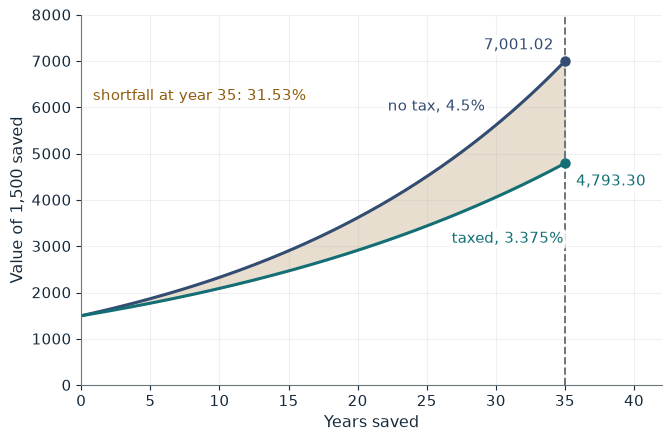

Net return            3.375%
No-tax value          7,001.02
Taxed value           4,793.30
Ratio taxed / no tax  0.6847
Shortfall             31.53%

Worked steps:
  1. Net return = 0.045(1 - 0.25) = 0.03375
  2. No tax: 1,500(1.045)^35 = 7,001.02
  3. Taxed: 1,500(1.03375)^35 = 4,793.30
  4. Ratio = 4,793.30 / 7,001.02 = 0.6847
  5. Shortfall = 1 - 0.6847 = 31.53%

The net return is 0.045 x (1 - 0.25) = 0.03375. After 35 years 1,500 grows to 7,001.02 without the tax and 4,793.30 with it, a ratio of 0.6847. Each year the taxed path falls only 1.08% further behind, but the loss compounds: after 35 years the taxed saving is worth 31.53% less.


In [2]:
show(capital_tax_picture(tau=0.25, years=35))

Change one input, `years`, and hold the others at the book's values:

In [3]:
sweep(capital_tax_picture, 'years', [10, 20, 35], {'tau': 0.25}, ['No-tax value', 'Taxed value', 'Shortfall'])

years | No-tax value | Taxed value | Shortfall
10 | 2,329.45 | 2,090.48 | 10.26%
20 | 3,617.57 | 2,913.41 | 19.47%
35 | 7,001.02 | 4,793.30 | 31.53%


The shortfall is 10.26% at 10 years and 31.53% at 35: the same annual rate penalizes long postponement much more.

## 2. Ramsey inverse-elasticity rule: tax the inelastic good more

$$\frac{\Delta q_i^c}{q_i}\approx\varepsilon_i^c\tau_i$$

$$\tau_b=\frac{0.012}{0.40}=0.03, \qquad \tau_d=\frac{0.012}{1.20}=0.01$$

$$R=0.60(988)+0.40(494)=790.4$$

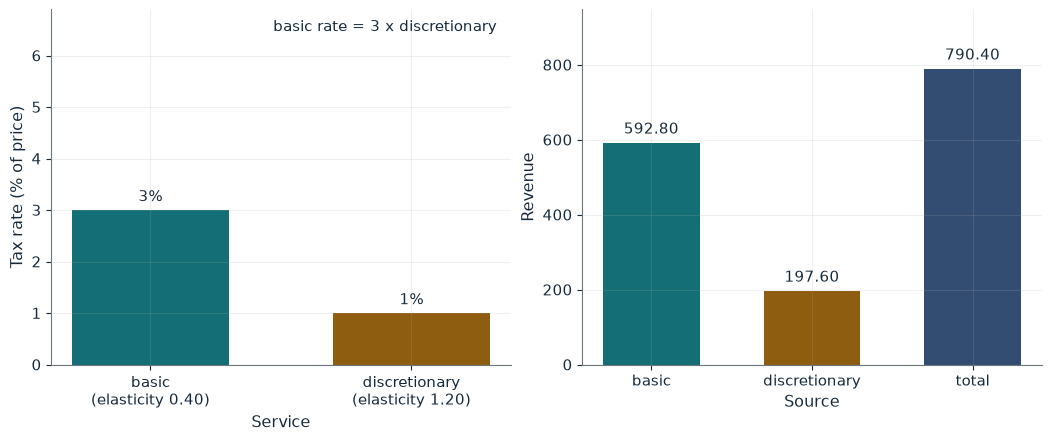

Basic rate tau_b          0.03
Discretionary rate tau_d  0.01
Rate ratio                3
Quantities after tax      988 and 494
Unit taxes                0.60 and 0.40
Revenue                   790.40

Worked steps:
  1. tau_b = 0.012 / 0.40 = 0.03
  2. tau_d = 0.012 / 1.20 = 0.01
  3. x_b' = 1,000(1 - 0.012) = 988; x_d' = 500(1 - 0.012) = 494
  4. Unit taxes: 0.03(20) = 0.60; 0.01(40) = 0.40
  5. R = 0.60(988) + 0.40(494) = 592.80 + 197.60 = 790.40

To cut each compensated demand by 1.2%, the basic service needs 0.03 and the discretionary service 0.01. The basic rate is 3 times the discretionary rate because its demand is 3 times less elastic. Revenue is 592.80 + 197.60 = 790.40.


In [4]:
show(ramsey_picture(eps_d=-1.2, c=0.012))

Change one input, `eps_d`, and hold the others at the book's values:

In [5]:
sweep(ramsey_picture, 'eps_d', [-0.8, -1.2, -1.6], {'c': 0.012}, ['Basic rate tau_b', 'Discretionary rate tau_d', 'Rate ratio', 'Revenue'])

eps_d | Basic rate tau_b | Discretionary rate tau_d | Rate ratio | Revenue
-0.8 | 0.03 | 0.015 | 2 | 889.20
-1.2 | 0.03 | 0.01 | 3 | 790.40
-1.6 | 0.03 | 0.0075 | 4 | 741.00


The basic rate is three times the discretionary rate because its demand is one third as elastic; doubling the discretionary elasticity halves its rate.

## 3. Mirrlees tradeoff: how much can be redistributed before the able worker mimics

Honest high-type utility is $78{,}000-x$ and mimicking gives $44{,}000+x$:

$$78{,}000-x\ge44{,}000+x$$

$$x\le17{,}000$$

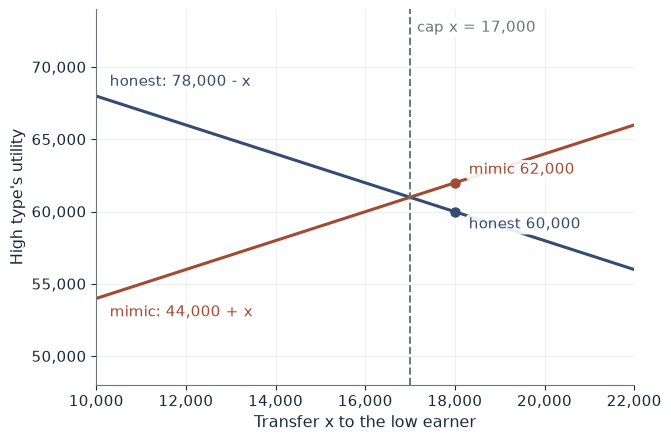

High type honest           60,000
High type mimicking        62,000
Incentive constraint       violated
Largest feasible transfer  17,000
Consumption, low and high  66,000 and 78,000

Worked steps:
  1. Honest: 96,000 - 18,000 - 18,000 = 60,000
  2. Mimic: 48,000 + 18,000 - 4,000 = 62,000
  3. Cap: 78,000 - x = 44,000 + x gives x = 34,000 / 2 = 17,000
  4. Consumption: 48,000 + 18,000 = 66,000 and 96,000 - 18,000 = 78,000, total 144,000

With a transfer of 18,000, the high type's honest utility is 78,000 - 18,000 = 60,000 and mimicking gives 48,000 + 18,000 - 4,000 = 62,000. Mimicking pays 2,000 more, so the high type takes the low bundle and the plan fails. With a mimicking cost of 4,000 the largest feasible transfer is 17,000.


In [6]:
show(mirrlees_picture(c=4000, x=18000))

Change one input, `x`, and hold the others at the book's values:

In [7]:
sweep(mirrlees_picture, 'x', [15000, 17000, 18000], {'c': 4000}, ['High type honest', 'High type mimicking', 'Incentive constraint'])

x | High type honest | High type mimicking | Incentive constraint
15000 | 63,000 | 59,000 | holds
17000 | 61,000 | 61,000 | holds, just binding
18000 | 60,000 | 62,000 | violated


A transfer of 18,000 gives 60,000 honest against 62,000 mimicking, so it fails; 17,000 just binds at 61,000 each. With costless mimicking (`c=0`) the cap falls to 15,000.

## 4. Ramsey social-discounting rule: the rate rides on growth

$$r=0.8\%+1.4(1.8\%)=3.32\%$$

$$PV=\frac{120}{(1.0332)^{35}}\approx38.26$$

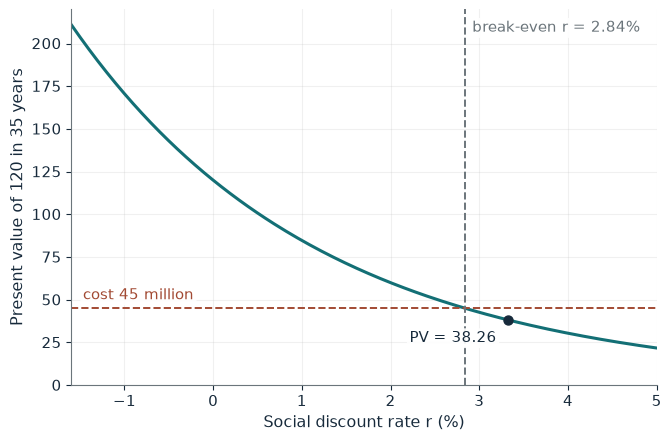

Discount rate r          3.32%
Present value (million)  38.26
Cost (million)           45
Project                  fails

Worked steps:
  1. r = 0.8% + 1.4(1.8%) = 3.32%
  2. PV = 120 / (1.0332)^35 = 38.26
  3. 38.26 < 45, so the project fails

The Ramsey rate is 0.8% + 1.4 x 1.8% = 3.32%. Discounted over 35 years, the 120 million benefit is worth 38.26 million today, below the 45 million cost, so the project fails. Any rate below 2.84% would pass it.


In [8]:
show(discount_picture(g=0.018, eta=1.4))

Change one input, `g`, and hold the others at the book's values:

In [9]:
sweep(discount_picture, 'g', [-0.01, 0.004, 0.018], {'eta': 1.4}, ['Discount rate r', 'Present value (million)', 'Project'])

g | Discount rate r | Present value (million) | Project
-0.01 | -0.60% | 148.14 | passes
0.004 | 1.36% | 74.79 | passes
0.018 | 3.32% | 38.26 | fails


At 1.8% growth the 120 million is worth 38.26 million and the 45 million project fails; at 0.4% growth it is worth 74.79 million and passes. The chapter prints the rate for falling consumption, -0.6%, but not its present value; 148.14 here is computed.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

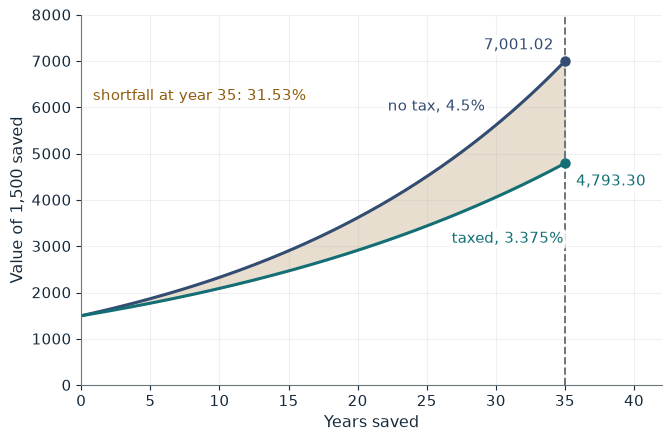

Net return            3.375%
No-tax value          7,001.02
Taxed value           4,793.30
Ratio taxed / no tax  0.6847
Shortfall             31.53%

Worked steps:
  1. Net return = 0.045(1 - 0.25) = 0.03375
  2. No tax: 1,500(1.045)^35 = 7,001.02
  3. Taxed: 1,500(1.03375)^35 = 4,793.30
  4. Ratio = 4,793.30 / 7,001.02 = 0.6847
  5. Shortfall = 1 - 0.6847 = 31.53%

The net return is 0.045 x (1 - 0.25) = 0.03375. After 35 years 1,500 grows to 7,001.02 without the tax and 4,793.30 with it, a ratio of 0.6847. Each year the taxed path falls only 1.08% further behind, but the loss compounds: after 35 years the taxed saving is worth 31.53% less.


In [10]:
show(capital_tax_picture(tau=0.25, years=35))

## Practice

**1.** At a 10-year horizon with the 25 percent tax, what is the shortfall?

<details><summary>Answer</summary>

1,500(1.045)^10 = 2,329.45 and 1,500(1.03375)^10 = 2,090.48, so the shortfall is 1 - 2,090.48/2,329.45 = 10.26%.

</details>

**2.** With a target contraction of 0.024 and the book's elasticities, what are the two rates?

<details><summary>Answer</summary>

tau_b = 0.024/0.40 = 0.06 and tau_d = 0.024/1.20 = 0.02; the ratio stays 3.

</details>

**3.** With growth of 0.4 percent and eta 1.4, does the project pass?

<details><summary>Answer</summary>

r = 0.8% + 1.4(0.4%) = 1.36% and PV = 120/(1.0136)^35 = 74.79 > 45, so it passes.

</details>